In [1]:
import pandas as pd
from scipy import stats
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

In [2]:
alimentacion = pd.read_csv("./dataframes/alimentacion_df_limpio_DEs_categorias.csv", sep=',')

C:\Users\alexa\AppData\Local\Temp\ipykernel_6912\1460826861.py:1: DtypeWarning: Columns (8: categories) have mixed types. Specify dtype option on import or set low_memory=False.
  alimentacion = pd.read_csv("./dataframes/alimentacion_df_limpio_DEs_categorias.csv", sep=',')


In [3]:
alimentacion.info()

<class 'pandas.DataFrame'>
RangeIndex: 331165 entries, 0 to 331164
Data columns (total 41 columns):
 #   Column                        Non-Null Count   Dtype  
---  ------                        --------------   -----  
 0   created_datetime              331165 non-null  str    
 1   last_modified_datetime        331165 non-null  str    
 2   product_name                  331165 non-null  str    
 3   quantity                      87220 non-null   str    
 4   packaging                     19976 non-null   str    
 5   packaging_tags                19966 non-null   str    
 6   packaging_en                  19966 non-null   str    
 7   brands                        331165 non-null  str    
 8   categories                    84653 non-null   str    
 9   categories_tags               125105 non-null  str    
 10  categories_en                 331165 non-null  str    
 11  origins_en                    9481 non-null    str    
 12  manufacturing_places_tags     12280 non-null   str    


In [4]:
alimentacion["labels_en"].head(30)

0                                         Made in Italy
1     Vegetarian,Organic,EU Organic,Kosher,Vegan,ES-...
2                                       Sin información
3                                             Green Dot
4                                       Sin información
5                                       Sin información
6               Nutriscore,Green Dot,Nutriscore Grade A
7     No gluten,No GMOs,Kosher,Non GMO project,Ortho...
8                                           en:Verified
9     Organic,Kosher,No GMOs,USDA Organic,Non GMO pr...
10                                      Sin información
11                 Green Dot,Made in Germany,es:natural
12                                      Sin información
13                                      Sin información
14                                      Sin información
15                                      Sin información
16                                        Contains GMOs
17                                            No

In [5]:
alimentacion["labels_en"].value_counts()

labels_en
Sin información                                                                  216133
Green Dot                                                                         22488
No gluten                                                                         18006
No gluten,Green Dot                                                                4883
No gluten,No lactose                                                               2876
                                                                                  ...  
No artificial colors,No artificial flavors,No preservatives                           1
FSC,FSC Mix,Green Dot,es:BABUTA                                                       1
No artificial flavors,No colorings,No preservatives,Made in France,No flavors         1
Vegetarian,Vegan,ISO 22716                                                            1
With sulfites,es:Denominación origen protejida                                        1
Name: count, Length: 1

In [6]:
alimentacion['etiquetas_interes'] = "Sin claim"

In [7]:
alimentacion['etiquetas_interes'].info()

<class 'pandas.Series'>
RangeIndex: 331165 entries, 0 to 331164
Series name: etiquetas_interes
Non-Null Count   Dtype
--------------   -----
331165 non-null  str  
dtypes: str(1)
memory usage: 2.5 MB


In [8]:
alimentacion[alimentacion["labels_en"].str.contains("zero", case=False)][["product_name", "labels_en"]]

,product_name,labels_en
8394,Fondant Dark,"Vegetarian,No gluten,Vegan,Green Dot,en:Zero s..."
8823,Light & free melocotón y fruta de la pasión,es:triple-zero
9495,Leche semidesnatada sin lactosa,"No lactose,es:Recomendado por ADILAC,es:Zero L..."
17844,Kefir Bianco Naturale,"No gluten,No GMOs,No preservatives,No lactose,..."
42943,Mermelada Fresas 0%,"No gluten,es:Zero-azucar-refinado"
56692,Syrup flavor chocolate,"en:0-calories,en:zero"
162580,Hola Cola,es:Cola Zero Zero


In [9]:
alimentacion.loc[(alimentacion["labels_en"].str.contains("zero", case=False)) | (alimentacion["product_name"].str.contains("zero", case=False)), 'etiquetas_interes'] = "zero azucar"

In [10]:
alimentacion.loc[(alimentacion["labels_en"].str.contains("light", case=False) | (alimentacion["product_name"].str.contains("light", case=False))), 'etiquetas_interes'] = "light"

In [11]:
alimentacion.loc[alimentacion["labels_en"].str.contains("vegan", case=False), 'etiquetas_interes'] = "vegano"

In [12]:
alimentacion.loc[alimentacion["labels_en"].str.contains("no gluten", case=False), 'etiquetas_interes'] = "sin gluten"

In [15]:
alimentacion['etiquetas_interes'].value_counts()

etiquetas_interes
Sin claim      281304
sin gluten      40248
vegano           7586
light            1198
zero azucar       829
Name: count, dtype: int64

In [16]:
alimentacion.groupby("categoria_principal")["etiquetas_interes"].count().sort_values(ascending=False)

categoria_principal
Plant-based foods and beverages         41359
Snacks                                  17948
Dairies                                 12186
Meats and their products                 9977
Beverages and beverages preparations     7786
                                        ...  
vitamins                                    1
vegan-chicken                               1
tés                                         1
truffle-oil                                 1
süßer-snack                                 1
Name: etiquetas_interes, Length: 581, dtype: int64

--- % de productos con DEs por categoría y claim ---
etiquetas_interes                     light  sin claim  sin gluten  vegano  \
categoria_principal                                                          
Beverages and beverages preparations  37.50      10.41       13.91    6.16   
Condiments                            16.00       5.28       14.16    4.69   
Dairies                                1.45       3.40        5.42    0.00   
Meats and their products              50.00       8.01       19.18    0.00   
Plant-based foods and beverages       17.20       2.39        6.04    3.30   
Seafood                                0.00       0.81        2.91    0.00   
Snacks                                 4.76       3.92        7.04    3.39   

etiquetas_interes                     zero azucar  
categoria_principal                                
Beverages and beverages preparations        67.42  
Condiments                                  22.22  
Dairies                             

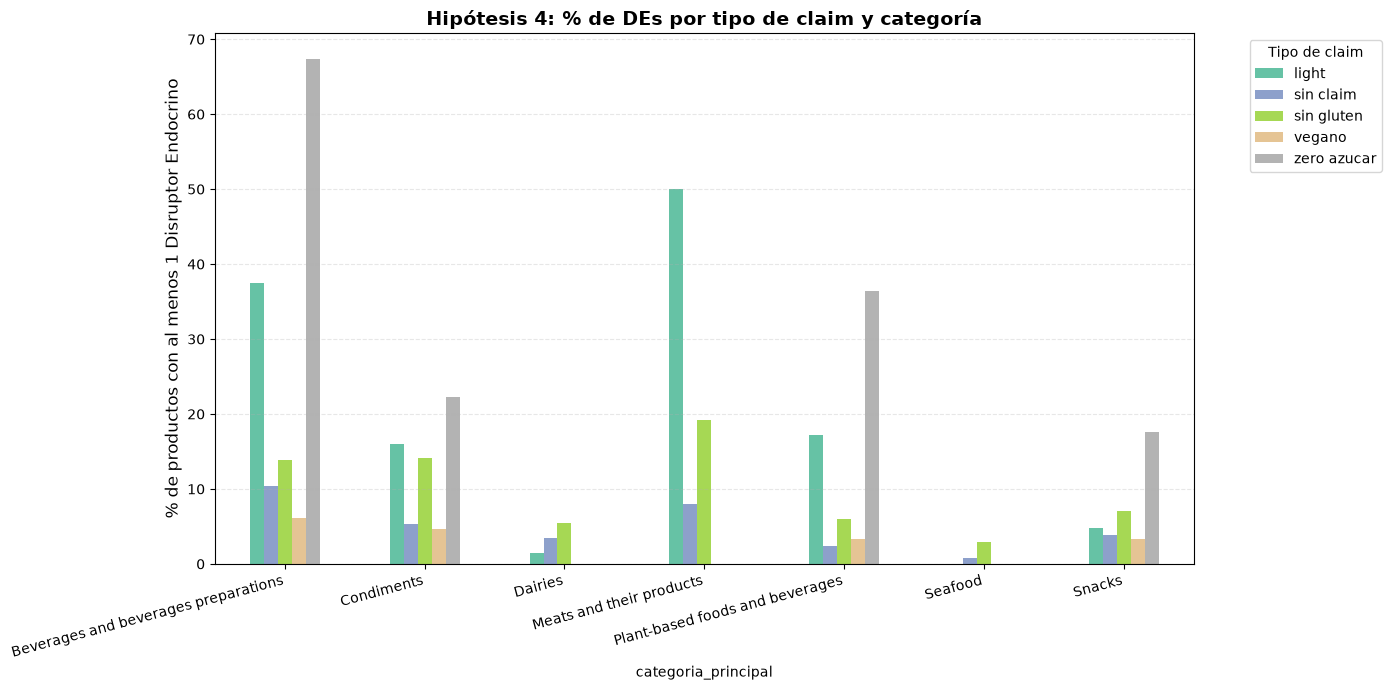

In [18]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Asegurar columna booleana de DEs
alimentacion['tiene_algun_DE'] = alimentacion['cantidad_posibles_DEs'] > 0

# 2. Rellenar NaN con 'Sin claim'
alimentacion['etiquetas_interes'] = alimentacion['etiquetas_interes'].fillna('Sin claim').str.lower().str.strip()

# 3. Categorías relevantes
categorias_relevantes = ['Plant-based foods and beverages', 
                         'Dairies', 'Snacks', 'Meats and their products', 
                         'Beverages and beverages preparations', 'Seafood', 'Condiments']

# 4. Filtrar
df_claims = alimentacion[alimentacion['categoria_principal'].isin(categorias_relevantes)].copy()

# 5. Calcular % de DEs por categoría y claim específico
resultado_claims = df_claims.groupby(['categoria_principal', 'etiquetas_interes'])['tiene_algun_DE'].mean() * 100

# 6. Reorganizar en matriz
tabla_claims = resultado_claims.unstack(level='etiquetas_interes')

# 7. Rellenar NaN con 0
tabla_claims = tabla_claims.fillna(0)

print("--- % de productos con DEs por categoría y claim ---")
print(tabla_claims.round(2))

# 8. Gráfico de barras agrupadas
fig, ax = plt.subplots(figsize=(14, 7))
tabla_claims.plot(kind='bar', ax=ax, colormap='Set2', figsize=(14, 7))

ax.set_ylabel('% de productos con al menos 1 Disruptor Endocrino', fontsize=12)
ax.set_title('Hipótesis 4: % de DEs por tipo de claim y categoría', fontsize=14, fontweight='bold')
ax.legend(title='Tipo de claim', bbox_to_anchor=(1.05, 1), loc='upper left')
ax.set_xticklabels(ax.get_xticklabels(), rotation=15, ha='right')
ax.grid(axis='y', alpha=0.3, linestyle='--')

plt.tight_layout()
plt.show()

In [ ]:
tabla_claims

etiquetas_interes,,light,sin gluten,vegano,zero azúcar
categoria_principal,,,,,
Beverages and beverages preparations,0.329774,1.785714,0.120919,0.000000,0.561798
Condiments,0.265487,0.000000,0.532481,0.781250,0.000000
Dairies,0.052007,0.000000,0.000000,0.000000,0.000000
Meats and their products,0.061246,0.000000,0.116414,0.000000,NaN
Plant-based foods and beverages,0.169322,0.000000,0.191278,0.067958,0.000000
Seafood,0.035273,0.000000,0.000000,0.000000,NaN
Snacks,1.077526,0.000000,0.905736,0.645161,0.000000


In [33]:
import statsmodels.formula.api as smf

# 1. Creamos una copia o una columna auxiliar numérica para la variable dependiente
alimentacion['tiene_algun_DE_int'] = alimentacion['tiene_algun_DE'].astype(int)

# 2. Ajustamos el modelo usando la nueva columna numérica
modelo_claims = smf.logit("tiene_algun_DE_int ~ C(etiquetas_interes) + C(nova_group)", data=alimentacion).fit()

# 3. Mostramos el resumen
print(modelo_claims.summary())

Optimization terminated successfully.
         Current function value: 0.052390
         Iterations 12
                           Logit Regression Results                           
Dep. Variable:     tiene_algun_DE_int   No. Observations:               331165
Model:                          Logit   Df Residuals:                   331156
Method:                           MLE   Df Model:                            8
Date:               ma., 10 nov. 2026   Pseudo R-squ.:                  0.4943
Time:                        21:04:47   Log-Likelihood:                -17350.
converged:                       True   LL-Null:                       -34309.
Covariance Type:            nonrobust   LLR p-value:                     0.000
                                          coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------------------------
Intercept                              -6.9011      0.179

Sin embargo, hay claims que seguro que se solapan. Ej: light y vegano.

In [39]:
import pandas as pd
import statsmodels.formula.api as smf

# 1. Creamos una columna base por defecto
alimentacion['etiquetas_interes'] = 'sin claim'

# 2. Aplicamos tus filtros con .str.contains (puedes añadir las condiciones que quieras)
# Usamos na=False para evitar errores si hay valores vacíos (NaN) en las columnas
mask_light = alimentacion["labels_en"].str.contains("light", case=False, na=False) | alimentacion["product_name"].str.contains("light", case=False, na=False)
mask_vegano = alimentacion["labels_en"].str.contains("vegan|plant-based", case=False, na=False) | alimentacion["product_name"].str.contains("vegan", case=False, na=False)
mask_gluten = alimentacion["labels_en"].str.contains("gluten-free|sin gluten|no gluten|no-gluten", case=False, na=False) | alimentacion["product_name"].str.contains("gluten", case=False, na=False)
mask_zero = alimentacion["labels_en"].str.contains("zero|sugar-free|sin azucar", case=False, na=False) | alimentacion["product_name"].str.contains("zero|sin azucar", case=False, na=False)

# Asignamos las etiquetas (si un producto cumple varias, puedes decidir el orden de prioridad o dejarlas combinadas)
alimentacion.loc[mask_light, 'etiquetas_interes'] = 'light'
alimentacion.loc[mask_vegano, 'etiquetas_interes'] = 'vegano'
alimentacion.loc[mask_gluten, 'etiquetas_interes'] = 'sin gluten'
alimentacion.loc[mask_zero, 'etiquetas_interes'] = 'zero azucar'

# (Opcional) Si quieres ver cuántos productos tienes de cada tipo para comprobar que todo va bien:
print(alimentacion['etiquetas_interes'].value_counts())

# 3. Preparamos la variable dependiente numérica para el modelo
alimentacion['tiene_algun_DE_int'] = alimentacion['tiene_algun_DE'].astype(int)

# 4. Ejecutamos el modelo de regresión logística de forma limpia
modelo_claims = smf.logit(
    "tiene_algun_DE_int ~ C(etiquetas_interes) + C(nova_group)", 
    data=alimentacion
).fit()

print(modelo_claims.summary())

etiquetas_interes
sin claim      279796
sin gluten      40328
vegano           8598
zero azucar      1251
light            1192
Name: count, dtype: int64
Optimization terminated successfully.
         Current function value: 0.052401
         Iterations 12
                           Logit Regression Results                           
Dep. Variable:     tiene_algun_DE_int   No. Observations:               331165
Model:                          Logit   Df Residuals:                   331156
Method:                           MLE   Df Model:                            8
Date:               ma., 10 nov. 2026   Pseudo R-squ.:                  0.4942
Time:                        21:22:42   Log-Likelihood:                -17353.
converged:                       True   LL-Null:                       -34309.
Covariance Type:            nonrobust   LLR p-value:                     0.000
                                          coef    std err          z      P>|z|      [0.025      0.975]
-------

In [43]:
import pandas as pd
import statsmodels.formula.api as smf

# 1. Creamos un DataFrame auxiliar de booleanos evaluando directamente la columna original 'labels_en'
df_claims = pd.DataFrame(index=alimentacion.index)

# Detectamos cada término clave de forma independiente en el texto original
df_claims['light'] = alimentacion["labels_en"].str.contains("light", case=False, na=False) | alimentacion["product_name"].str.contains("light", case=False, na=False)
df_claims['plant-based'] = alimentacion["labels_en"].str.contains("vegan|plant-based|vegetarian", case=False, na=False) | alimentacion["product_name"].str.contains("vegan|plant-based|vegetarian", case=False, na=False)
df_claims['sin gluten'] = alimentacion["labels_en"].str.contains("no gluten|sin gluten|no-gluten", case=False, na=False) | alimentacion["product_name"].str.contains("gluten", case=False, na=False)
df_claims['zero azucar'] = alimentacion["labels_en"].str.contains("zero|sugar-free|sin azucar", case=False, na=False) | alimentacion["product_name"].str.contains("zero|sin azucar", case=False, na=False)

# 2. Función para juntar en una misma categoría todas las etiquetas que se activen en la misma fila
def juntar_claims(row):
    activos = [col for col, val in row.items() if val]
    if not activos:
        return 'sin claim'
    # Las ordena alfabéticamente para que 'sin gluten + vegano' sea siempre idéntico
    return ' + '.join(sorted(activos))

# Aplicamos la función para generar la nueva columna combinada real
alimentacion['etiquetas_combinadas'] = df_claims.apply(juntar_claims, axis=1)

# 3. Comprobamos el resultado (¡aquí ya deberían aparecer los combos como 'sin gluten + vegano'!)
print("--- Conteo real de etiquetas y combinaciones ---")
print(alimentacion['etiquetas_combinadas'].value_counts())

--- Conteo real de etiquetas y combinaciones ---
etiquetas_combinadas
sin claim                                 278403
sin gluten                                 36376
plant-based                                 9976
plant-based + sin gluten                    3594
light                                       1190
zero azucar                                 1055
light + sin gluten                           341
sin gluten + zero azucar                     137
plant-based + zero azucar                     40
light + plant-based                           20
plant-based + sin gluten + zero azucar        14
light + plant-based + sin gluten              14
light + zero azucar                            5
Name: count, dtype: int64


In [45]:
# 1. Verificamos el conteo actual
conteo = alimentacion['etiquetas_combinadas'].value_counts()

# 2. Definimos un umbral mínimo (ej. n >= 50) para mantener la categoría separada
umbral = 50
categorias_validas = conteo[conteo >= umbral].index

# 3. Agrupamos las minoritarias en "Otras combinaciones"
alimentacion['etiquetas_limpias'] = alimentacion['etiquetas_combinadas'].apply(
    lambda x: x if x in categorias_validas else 'Otras combinaciones'
)

print("--- Conteo depurado para el modelo ---")
print(alimentacion['etiquetas_limpias'].value_counts())

--- Conteo depurado para el modelo ---
etiquetas_limpias
sin claim                   278403
sin gluten                   36376
plant-based                   9976
plant-based + sin gluten      3594
light                         1190
zero azucar                   1055
light + sin gluten             341
sin gluten + zero azucar       137
Otras combinaciones             93
Name: count, dtype: int64


In [46]:
# 4. Ejecutamos el modelo final con esta variable limpia
modelo_final = smf.logit(
    "tiene_algun_DE_int ~ C(etiquetas_limpias) + C(nova_group)", 
    data=alimentacion
).fit()

print(modelo_final.summary())

Optimization terminated successfully.
         Current function value: 0.051854
         Iterations 12
                           Logit Regression Results                           
Dep. Variable:     tiene_algun_DE_int   No. Observations:               331165
Model:                          Logit   Df Residuals:                   331152
Method:                           MLE   Df Model:                           12
Date:               ma., 10 nov. 2026   Pseudo R-squ.:                  0.4995
Time:                        21:33:03   Log-Likelihood:                -17172.
converged:                       True   LL-Null:                       -34309.
Covariance Type:            nonrobust   LLR p-value:                     0.000
                                                       coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------------------------------------
Intercept                      

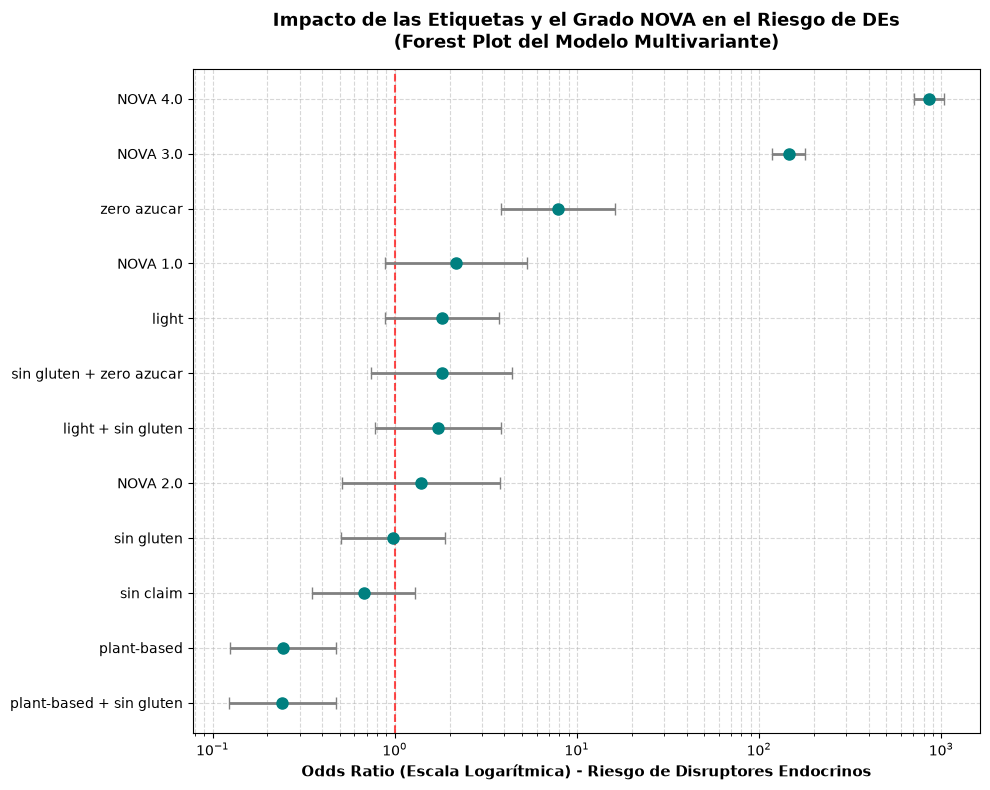

In [47]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# 1. Extraemos los Odds Ratios (exponenciando los coeficientes) y los intervalos de confianza del modelo
params = modelo_final.params
conf = modelo_final.conf_int()
conf['OR'] = np.exp(params)
conf['CI_low'] = np.exp(conf[0])
conf['CI_high'] = np.exp(conf[1])

# Creamos un DataFrame limpio con los resultados (excluyendo el Intercept)
df_results = pd.DataFrame({
    'Variable': conf.index,
    'OR': conf['OR'],
    'CI_low': conf['CI_low'],
    'CI_high': conf['CI_high']
}).drop(index='Intercept')

# Limpiamos los nombres para que se lean mejor en el gráfico
df_results['Variable'] = df_results['Variable'].str.replace('C(etiquetas_limpias)[T.', '').str.replace('C(nova_group)[T.', 'NOVA ').str.replace(']', '')

# Ordenamos los resultados para que se vea ordenado
df_results = df_results.sort_values(by='OR', ascending=True)

# 2. Dibujamos el Forest Plot
plt.figure(figsize=(10, 8))

# Línea vertical de referencia en OR = 1 (sin efecto / neutral)
plt.axvline(x=1, color='red', linestyle='--', alpha=0.7, label='Línea de referencia (Sin efecto)')

# Puntos para los Odds Ratios y barras de error para los intervalos de confianza (IC del 95%)
plt.errorbar(
    x=df_results['OR'], 
    y=df_results['Variable'], 
    xerr=[df_results['OR'] - df_results['CI_low'], df_results['CI_high'] - df_results['OR']],
    fmt='o', color='teal', ecolor='gray', elinewidth=2, capsize=4, markersize=8
)

# Configuraciones estéticas del gráfico
plt.xscale('log') # Escala logarítmica recomendada para Odds Ratios altos (como los de NOVA 4)
plt.xlabel('Odds Ratio (Escala Logarítmica) - Riesgo de Disruptores Endocrinos', fontsize=11, fontweight='bold')
plt.title('Impacto de las Etiquetas y el Grado NOVA en el Riesgo de DEs\n(Forest Plot del Modelo Multivariante)', fontsize=13, fontweight='bold', pad=15)
plt.grid(True, which="both", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

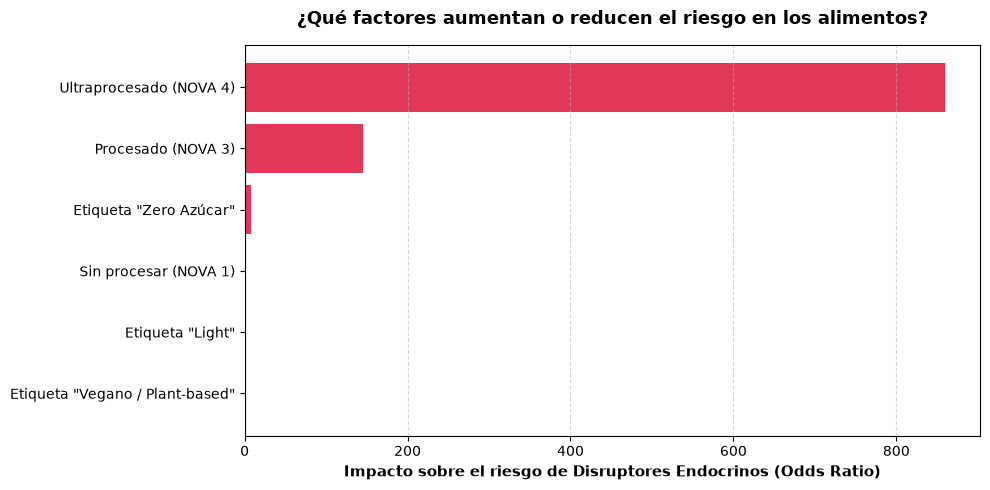

In [49]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# 1. Extraemos los Odds Ratios directamente del modelo final actual
params = modelo_final.params
conf = modelo_final.conf_int()
conf['OR'] = np.exp(params)

df_results = pd.DataFrame({
    'Variable': conf.index,
    'OR': conf['OR']
}).drop(index='Intercept')

# 2. Diccionario con nombres amigables para el público general
nombres_amigables = {
    'C(nova_group)[T.4.0]': 'Ultraprocesado (NOVA 4)',
    'C(nova_group)[T.3.0]': 'Procesado (NOVA 3)',
    'C(etiquetas_limpias)[T.zero azucar]': 'Etiqueta "Zero Azúcar"',
    'C(etiquetas_limpias)[T.light]': 'Etiqueta "Light"',
    'C(etiquetas_limpias)[T.plant-based]': 'Etiqueta "Vegano / Plant-based"',
    'C(nova_group)[T.1.0]': 'Sin procesar (NOVA 1)'
}

# Filtramos solo las variables clave para no saturar al público
df_publi = df_results[df_results['Variable'].isin(nombres_amigables.keys())].copy()
df_publi['Variable'] = df_publi['Variable'].map(nombres_amigables)
df_publi = df_publi.sort_values(by='OR', ascending=True)

# 3. Dibujamos el gráfico de barras horizontales
plt.figure(figsize=(10, 5))

# Colores dinámicos: rojo si aumenta el riesgo (>1), verde si lo reduce o es neutro (<=1)
colores = ['forestgreen' if val < 1 else 'crimson' for val in df_publi['OR']]

bars = plt.barh(df_publi['Variable'], df_publi['OR'], color=colores, alpha=0.85)

# Línea de referencia de "riesgo neutro" (en 1)
plt.axvline(x=1, color='black', linestyle='--', alpha=0.6, label='Sin riesgo extra (Línea base)')

plt.xlabel('Impacto sobre el riesgo de Disruptores Endocrinos (Odds Ratio)', fontsize=11, fontweight='bold')
plt.title('¿Qué factores aumentan o reducen el riesgo en los alimentos?', fontsize=13, fontweight='bold', pad=15)
plt.grid(axis='x', linestyle='--', alpha=0.5)

# Asegurar que se muestre correctamente en pantalla
plt.tight_layout()
plt.show()

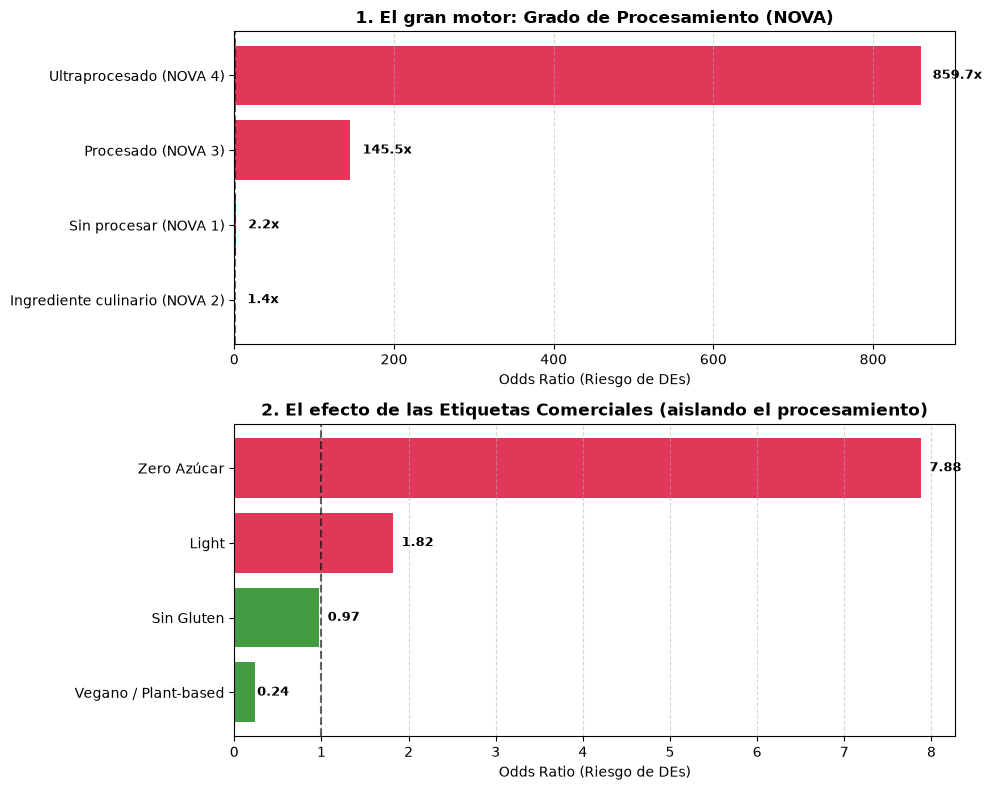

In [50]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# 1. Extraemos los datos del modelo final
params = modelo_final.params
conf = modelo_final.conf_int()
conf['OR'] = np.exp(params)

df_results = pd.DataFrame({
    'Variable': conf.index,
    'OR': conf['OR']
}).drop(index='Intercept')

# 2. Separamos los datos en dos grupos lógicos para que no compitan en la misma escala
nova_vars = ['C(nova_group)[T.1.0]', 'C(nova_group)[T.2.0]', 'C(nova_group)[T.3.0]', 'C(nova_group)[T.4.0]']
label_vars = [
    'C(etiquetas_limpias)[T.zero azucar]', 
    'C(etiquetas_limpias)[T.light]', 
    'C(etiquetas_limpias)[T.plant-based]',
    'C(etiquetas_limpias)[T.sin gluten]'
]

nombres_nova = {
    'C(nova_group)[T.1.0]': 'Sin procesar (NOVA 1)',
    'C(nova_group)[T.2.0]': 'Ingrediente culinario (NOVA 2)',
    'C(nova_group)[T.3.0]': 'Procesado (NOVA 3)',
    'C(nova_group)[T.4.0]': 'Ultraprocesado (NOVA 4)'
}

nombres_labels = {
    'C(etiquetas_limpias)[T.zero azucar]': 'Zero Azúcar',
    'C(etiquetas_limpias)[T.light]': 'Light',
    'C(etiquetas_limpias)[T.plant-based]': 'Vegano / Plant-based',
    'C(etiquetas_limpias)[T.sin gluten]': 'Sin Gluten'
}

df_nova = df_results[df_results['Variable'].isin(nova_vars)].copy()
df_nova['Variable'] = df_nova['Variable'].map(nombres_nova)
df_nova = df_nova.sort_values(by='OR', ascending=True)

df_labels = df_results[df_results['Variable'].isin(label_vars)].copy()
df_labels['Variable'] = df_labels['Variable'].map(nombres_labels)
df_labels = df_labels.sort_values(by='OR', ascending=True)

# 3. Creamos una figura con dos paneles (subplots apilados)
fig, (ax1, ax2) = plt.subplots(nrows=2, ncols=1, figsize=(10, 8), sharex=False)

# --- PANEL 1: El impacto del Grado NOVA ---
colores_nova = ['crimson' if val > 1 else 'forestgreen' for val in df_nova['OR']]
bars1 = ax1.barh(df_nova['Variable'], df_nova['OR'], color=colores_nova, alpha=0.85)
ax1.axvline(x=1, color='black', linestyle='--', alpha=0.6)
ax1.set_title('1. El gran motor: Grado de Procesamiento (NOVA)', fontsize=12, fontweight='bold')
ax1.set_xlabel('Odds Ratio (Riesgo de DEs)', fontsize=10)
ax1.grid(axis='x', linestyle='--', alpha=0.5)

# Añadir etiquetas de texto con el valor exacto al lado de cada barra en NOVA
for bar in bars1:
    width = bar.get_width()
    ax1.text(width + 15, bar.get_y() + bar.get_height()/2, f'{width:.1f}x', 
             va='center', ha='left', fontsize=9, fontweight='bold')

# --- PANEL 2: El impacto de las Etiquetas ---
colores_labels = ['crimson' if val > 1 else 'forestgreen' for val in df_labels['OR']]
bars2 = ax2.barh(df_labels['Variable'], df_labels['OR'], color=colores_labels, alpha=0.85)
ax2.axvline(x=1, color='black', linestyle='--', alpha=0.6)
ax2.set_title('2. El efecto de las Etiquetas Comerciales (aislando el procesamiento)', fontsize=12, fontweight='bold')
ax2.set_xlabel('Odds Ratio (Riesgo de DEs)', fontsize=10)
ax2.grid(axis='x', linestyle='--', alpha=0.5)

# Añadir etiquetas de texto en las barras de etiquetas
for bar in bars2:
    width = bar.get_width()
    # Si el valor es menor que 1, ajustamos la posición del texto para que no se corte
    offset = 0.1 if width > 0.5 else 0.02
    ax2.text(width + offset, bar.get_y() + bar.get_height()/2, f'{width:.2f}', 
             va='center', ha='left', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.show()

In [59]:
alimentacion.to_csv("./dataframes/alimentacion_df_limpio_DEs_catg_etiq.csv", sep=',')